# Aşama 7: Tüm gökyüzü taraması

Şimdiye kadar "şu dört kaynağa bak" dedik. Burada **hiçbir yere işaret etmeden** kuzey gökyüzünün her noktasını tek tek test ediyoruz ve en sıcak noktayı arıyoruz. Bu, projenin tarafsız "keşif" kısmı.

Yeni bir sorun çıkıyor: **binlerce noktaya bakınca** bazıları şans eseri sıcak çıkar. Buna *look-elsewhere* (başka yere bakma) etkisi denir. En sıcak noktanın anlamlılığını bu yüzden düzeltmemiz gerekiyor: aynı taramayı karıştırılmış gökyüzlerinde de yapıp "sahte gökyüzlerinin en sıcak noktası ne kadar sıcak oluyor?" diye soruyoruz.

In [1]:
import sys; sys.path.append('../src')
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import icecube_ps as ps
importlib.reload(ps)
assert float(ps.SURUM) >= float('7.0'), f"src/icecube_ps.py eski sürüm ({getattr(ps, 'SURUM', 'yok')}). Yenisini kopyala, kernel'i yeniden başlat."
try:
    from tqdm.auto import tqdm          # ilerleme çubuğu
except ImportError:
    tqdm = None

pd.set_option('display.float_format', '{:.3g}'.format)
DATA, RESULTS = Path('../data'), Path('../results')
ev = ps.veri_yukle(DATA)
B = ps.ArkaPlan(ev['dec'].values)
print('icecube_ps', ps.SURUM, '| olay:', f'{len(ev):,}')

icecube_ps 14.0 | olay: 1,134,450


c:\Users\musab\Desktop\Projects\Claude_Notrino_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Gerçek gökyüzü haritası

Kuzey gökyüzünü (Dec −5° ile +85° arası) ~0.7° aralıklı ~46.000 noktaya bölüyoruz ve her noktada Aşama 3'teki fit'i yapıyoruz. ⏱️ 1–3 dakika.

In [2]:
ra_g, dec_g = ps.gok_izgarasi(adim=0.7)
T = ps.Tarayici(ev, B)
dosya = RESULTS / 'asama7_harita.npz'
if dosya.exists():
    h = np.load(dosya); ns_g, ts_g = h['ns'], h['ts']
else:
    ns_g, ts_g = T.harita(ra_g, dec_g, ilerleme=tqdm)
    np.savez(dosya, ra=ra_g, dec=dec_g, ns=ns_g, ts=ts_g)
p_g = ps.yerel_p(ts_g)
print(f'{len(ra_g):,} nokta tarandı')

45,859 nokta tarandı


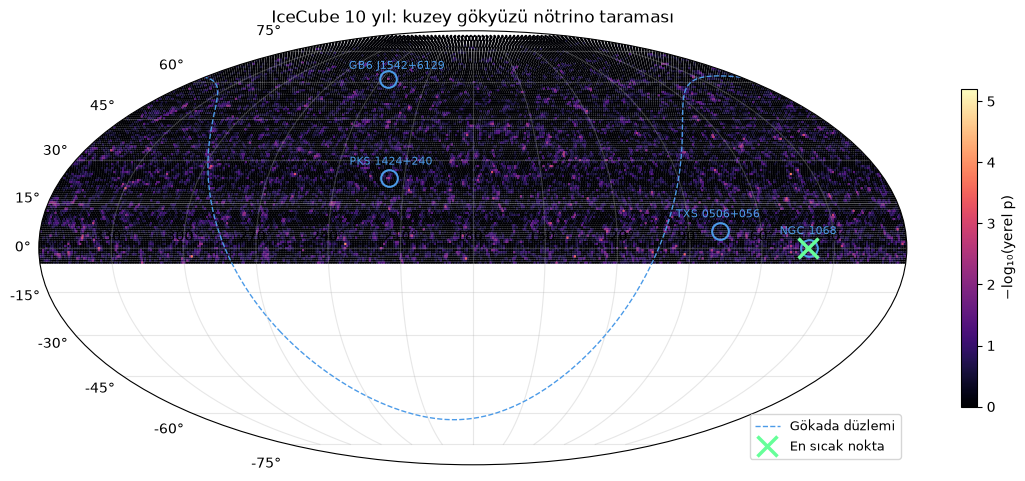

In [3]:
def gok_ekseni(ax_ra):
    return -(np.radians(ax_ra) - np.pi)          # Mollweide: RA sağdan sola

fig = plt.figure(figsize=(14, 7.5))
ax = fig.add_subplot(111, projection='mollweide')
renk = -np.log10(p_g)
sira = np.argsort(renk)
sc = ax.scatter(gok_ekseni(ra_g[sira]), np.radians(dec_g[sira]), c=renk[sira],
                s=3, cmap='magma', vmin=0, vmax=max(4, renk.max()), lw=0)
fig.colorbar(sc, ax=ax, shrink=0.55, label='−log₁₀(yerel p)')

gr, gd = ps.galaksi_duzlemi()
gx, gy = gok_ekseni(gr), np.radians(gd)
kopma = np.where(np.abs(np.diff(gx)) > np.pi)[0] + 1          # harita kenarında çizgiyi kes
gx, gy = np.insert(gx, kopma, np.nan), np.insert(gy, kopma, np.nan)
ax.plot(gx, gy, color='#4c9be8', lw=1, ls='--', label='Gökada düzlemi')
for ad, (rk, dk) in ps.KAYNAKLAR.items():
    ax.plot(gok_ekseni(rk), np.radians(dk), 'o', mfc='none', mec='#4c9be8', ms=12, mew=1.5)
    ax.text(gok_ekseni(rk), np.radians(dk) + 0.08, ad, color='#4c9be8', fontsize=8, ha='center')

en = np.argmax(ts_g)
ax.plot(gok_ekseni(ra_g[en]), np.radians(dec_g[en]), 'x', color='#66ff99', ms=14, mew=2.5,
        label='En sıcak nokta')
ax.set_xticks(np.radians(np.arange(-150, 151, 30)))
ax.set_xticklabels([f'{(180 - t) % 360:.0f}°' for t in np.arange(-150, 151, 30)])   # eksende RA yazsın
ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=9)
ax.set_title('IceCube 10 yıl: kuzey gökyüzü nötrino taraması')
plt.savefig(RESULTS / 'asama7_gok_haritasi.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. En sıcak nokta

En sıcak ızgara noktasının etrafında 0.1°'lik ince bir tarama yapıp konumunu netleştiriyoruz, sonra en yakın bilinen kaynağa uzaklığına bakıyoruz.

En sıcak nokta: RA = 40.87°, Dec = -0.40°
nₛ = 57.9, TS = 23.1, yerel anlamlılık = 4.81σ
En yakın bilinen kaynak: NGC 1068, 0.44° uzakta


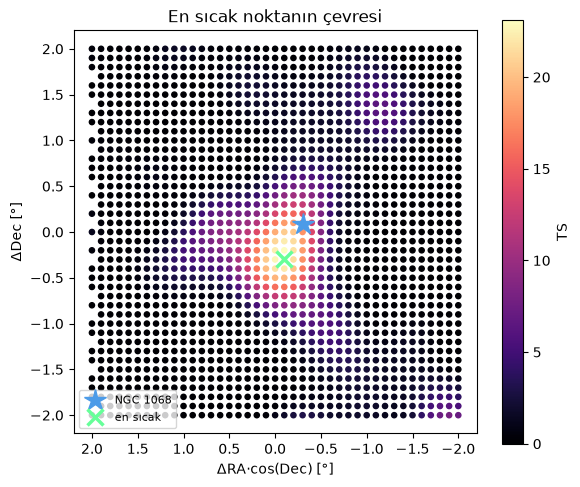

In [4]:
r0, d0 = ra_g[en], dec_g[en]
ince_d = np.round(np.arange(max(d0 - 2, -5), min(d0 + 2, 85) + 0.001, 0.1), 3)   # tarama bölgesinde kal
ince_ra, ince_dec = [], []
for d in ince_d:
    rr = np.arange(r0 - 2 / np.cos(np.radians(d)), r0 + 2 / np.cos(np.radians(d)), 0.1 / np.cos(np.radians(d)))
    ince_ra.append(rr % 360); ince_dec.append(np.full(len(rr), d))
ince_ra, ince_dec = np.concatenate(ince_ra), np.concatenate(ince_dec)
ns_i, ts_i = T.harita(ince_ra, ince_dec)
k = np.argmax(ts_i)
sicak = dict(ra=ince_ra[k], dec=ince_dec[k], ns=ns_i[k], TS=ts_i[k],
             yerel_sigma=ps.sigma(ps.yerel_p(ts_i[k])))
uzak = {ad: ps.acisal_uzaklik(sicak['ra'], sicak['dec'], rk, dk) for ad, (rk, dk) in ps.KAYNAKLAR.items()}
en_yakin = min(uzak, key=uzak.get)
print(f"En sıcak nokta: RA = {sicak['ra']:.2f}°, Dec = {sicak['dec']:.2f}°")
print(f"nₛ = {sicak['ns']:.1f}, TS = {sicak['TS']:.1f}, yerel anlamlılık = {sicak['yerel_sigma']:.2f}σ")
print(f"En yakın bilinen kaynak: {en_yakin}, {uzak[en_yakin]:.2f}° uzakta")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter((ince_ra - r0) * np.cos(np.radians(ince_dec)), ince_dec - d0, c=ts_i, s=14, cmap='magma')
fig.colorbar(sc, label='TS')
for ad, (rk, dk) in ps.KAYNAKLAR.items():
    if uzak[ad] < 3:
        ax.plot((rk - r0) * np.cos(np.radians(dk)), dk - d0, '*', color='#4c9be8', ms=16, label=ad)
ax.plot((sicak['ra'] - r0) * np.cos(np.radians(sicak['dec'])), sicak['dec'] - d0, 'x', color='#66ff99', ms=12, mew=2.5, label='en sıcak')
ax.set_xlim(2.2, -2.2); ax.set_aspect('equal')
ax.set_xlabel('ΔRA·cos(Dec) [°]'); ax.set_ylabel('ΔDec [°]'); ax.legend(fontsize=8)
ax.set_title('En sıcak noktanın çevresi')
plt.savefig(RESULTS / 'asama7_sicak_nokta.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. "Başka yere bakma" düzeltmesi

Karıştırılmış gökyüzlerinde aynı taramayı yapıp her birinin **en küçük yerel p-değerini** kaydediyoruz. Bunlardan "gökyüzünde kaç bağımsız nokta varmış gibi davranıyor" sayısını ($N_{\text{eff}}$) tahmin ediyoruz. Düzeltilmiş (post-trial) p-değeri:

$$p_{\text{post}} = 1 - (1 - p_{\text{yerel}})^{N_{\text{eff}}}$$

Sezgisi: $N_{\text{eff}}$ tane bağımsız şans biletin varsa, en az birinin tutma olasılığı tek bir biletinkinden çok daha yüksek.

⏱️ Her karıştırılmış harita 1–3 dakika. Varsayılan 30 harita (~1 saat). Her harita bitince kaydediliyor: istediğin zaman durdurup sonra kaldığın yerden devam edebilirsin. Ne kadar çok harita, o kadar kesin $N_{\text{eff}}$.

In [5]:
N_KARISIK = 30
dosya = RESULTS / 'asama7_karisik_min_p.npy'
min_p = list(np.load(dosya)) if dosya.exists() else []
rng = np.random.default_rng(len(min_p) + 100)        # devam ederken farklı tohum
dongu = range(len(min_p), N_KARISIK)
for i in (tqdm(dongu, desc='karıştırılmış haritalar') if tqdm else dongu):
    _, ts_k = T.harita(ra_g, dec_g, ra_olay=T.karisik_ra(rng))
    min_p.append(ps.yerel_p(ts_k.max()))
    np.save(dosya, np.array(min_p))
min_p = np.array(min_p)
print(f'{len(min_p)} karıştırılmış harita hazır')

karıştırılmış haritalar: 0it [00:00, ?it/s]

30 karıştırılmış harita hazır


Etkin bağımsız nokta sayısı  N_eff ≈ 9,980   (ızgarada 45,859 nokta)
En sıcak nokta  yerel (ızgara):  4.37σ
                post-trial:  1.55σ   (p = 0.061)
                (doğrudan sayım: 2/30 karıştırılmış harita daha sıcak)


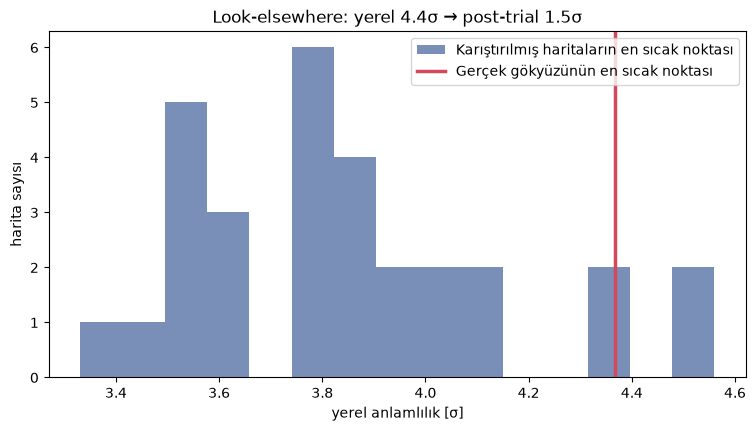

In [6]:
N_eff = ps.etkin_deneme_sayisi(min_p)
# ÖNEMLİ: anlamlılık için ızgaradaki en büyük TS kullanılır (karıştırılmış haritalarla AYNI işlem).
# İnce tarama sadece konum/nₛ tahmini için; onun TS'si ızgaradakinden hep biraz büyük çıkar
# ve karıştırılmış haritalarda ince tarama yapmadığımız için karşılaştırma haksız olurdu.
p_yerel = ps.yerel_p(ts_g.max())
p_post = 1 - (1 - p_yerel) ** N_eff
p_post_mc = (np.sum(min_p <= p_yerel) + 1) / (len(min_p) + 1)

print(f"Etkin bağımsız nokta sayısı  N_eff ≈ {N_eff:,.0f}   (ızgarada {len(ra_g):,} nokta)")
print(f"En sıcak nokta  yerel (ızgara):  {ps.sigma(p_yerel):.2f}σ")
print(f"                post-trial:  {ps.sigma(p_post):.2f}σ   (p = {p_post:.3g})")
print(f"                (doğrudan sayım: {np.sum(min_p <= p_yerel)}/{len(min_p)} karıştırılmış harita daha sıcak)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(ps.sigma(min_p), bins=15, color='#7a8fb8', label='Karıştırılmış haritaların en sıcak noktası')
ax.axvline(ps.sigma(p_yerel), color='#d1495b', lw=2.5, label='Gerçek gökyüzünün en sıcak noktası')
ax.set_xlabel('yerel anlamlılık [σ]'); ax.set_ylabel('harita sayısı'); ax.legend()
ax.set_title(f'Look-elsewhere: yerel {ps.sigma(p_yerel):.1f}σ → post-trial {ps.sigma(p_post):.1f}σ')
plt.savefig(RESULTS / 'asama7_post_trial.png', dpi=150, bbox_inches='tight')
plt.show()

pd.DataFrame([dict(**sicak, TS_izgara=ts_g.max(), en_yakin_kaynak=en_yakin, uzaklik_deg=uzak[en_yakin], N_eff=N_eff,
                   sigma_yerel=ps.sigma(p_yerel), sigma_post=ps.sigma(p_post),
                   n_karisik=len(min_p))]).to_csv(RESULTS / 'asama7_sicak_nokta.csv', index=False)

## Nasıl yorumlanır?

- **Haritada ne görüyoruz?** Çoğu yer rastgele "kumlanma": arka planın doğal dalgalanmaları. Asıl soru, en parlak noktanın bu kumlanmadan sıyrılıp sıyrılmadığı.
- **En sıcak nokta bir kaynağa denk geliyorsa** (IceCube'un makalesinde NGC 1068'e denk geliyordu), bu tarafsız bir taramanın bilinen bir kaynağı kendiliğinden bulması demek. Analizin en güçlü kanıtlarından biri.
- **Yerel ve post-trial farkı:** Binlerce noktaya bakmanın bedeli. 4σ'lık bir yerel sinyal post-trial'da 2–3σ'ya inebilir. Bilimde "keşif" iddiası post-trial sayıyla yapılır.
- **Sadeleştirmeler:** Sadece kuzey gökyüzü (güney zaten çok daha az hassas, Aşama 5), enerji bilgisi yok, karıştırılmış harita sayısı sınırlı. $N_{\text{eff}}$ tahmini harita sayısı arttıkça iyileşir.